In [1]:
import pandas as pd
import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential

In [2]:
df = pd.read_csv("/content/Churn_Modelling.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.isna().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [8]:
df.drop(['RowNumber', 'CustomerId', 'Surname'],axis=1,inplace=True)

In [9]:
df = pd.get_dummies(df,columns=["Geography","Gender"],drop_first=True)

In [10]:
X = df.copy()
X.drop("Exited",axis=1,inplace=True)
y = df[["Exited"]]

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=21)

In [13]:
import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential

In [14]:
from tensorflow.keras.layers import Dense

In [16]:
X.shape

(10000, 11)

# How to change a neural network archietecture
- Change the number of neurons
- change the number of hidden layes
- change the number of inputs
- Change the numer of neurons in the output layer

In [66]:
# initiating the model
model = Sequential()

In [67]:
# first hidden layer with 5 perceptrons,
model.add(Dense(3,activation="relu",input_dim=11))

# second hidden layer with 5 perceptrons,
#model.add(Dense(3,activation="relu"))

# output layer with one perceptron
model.add(Dense(1,activation="sigmoid"))

In [68]:
# compiling the model
# using adam optimizer as it is seem to perform good
# as our target variable is binary using binary_crossentropy
model.compile(loss="binary_crossentropy",optimizer="Adam",metrics=["accuracy"])

In [69]:
# fitting the model on training data
# taking 20% from training data for validation
# storing the model in a n object to assess the acuracy and loss
history = model.fit(X_train,y_train,epochs=10,validation_split=0.2)

Epoch 1/10
200/200 [==============================] - 1s 3ms/step - loss: 296.0294 - accuracy: 0.6914 - val_loss: 125.9337 - val_accuracy: 0.8006
Epoch 2/10
200/200 [==============================] - 0s 2ms/step - loss: 84.2877 - accuracy: 0.7141 - val_loss: 27.1395 - val_accuracy: 0.7663
Epoch 3/10
200/200 [==============================] - 1s 3ms/step - loss: 6.6268 - accuracy: 0.7675 - val_loss: 1.1679 - val_accuracy: 0.8012
Epoch 4/10
200/200 [==============================] - 1s 3ms/step - loss: 1.5526 - accuracy: 0.7734 - val_loss: 1.3136 - val_accuracy: 0.8000
Epoch 5/10
200/200 [==============================] - 1s 4ms/step - loss: 1.2080 - accuracy: 0.7723 - val_loss: 1.1006 - val_accuracy: 0.8000
Epoch 6/10
200/200 [==============================] - 1s 3ms/step - loss: 1.0531 - accuracy: 0.7711 - val_loss: 0.6934 - val_accuracy: 0.7412
Epoch 7/10
200/200 [==============================] - 1s 3ms/step - loss: 0.9986 - accuracy: 0.7728 - val_loss: 1.1419 - val_accuracy: 0.8000


In [70]:
# checking trainable parmeters of the model
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_18 (Dense)            (None, 3)                 36        
                                                                 
 dense_19 (Dense)            (None, 1)                 4         
                                                                 
Total params: 40
Trainable params: 40
Non-trainable params: 0
_________________________________________________________________


In [71]:
# extracting the weights of first layer
model.layers[0].get_weights()

[array([[ 0.02692343, -0.36813208,  0.00985132],
        [ 0.01752134,  0.35711   , -0.92211366],
        [-0.09150456, -0.5344815 ,  0.312166  ],
        [-0.00455058, -0.8368869 , -0.52810925],
        [ 0.35375538,  0.54963005, -0.13736384],
        [-0.02284211,  0.56283844, -0.34980482],
        [-0.40526408, -0.31923205,  0.20814799],
        [-0.59152263,  0.20363127,  0.05700604],
        [-0.34020132, -0.7490408 ,  0.02157085],
        [-0.16622129,  0.14791346, -0.758841  ],
        [-0.51764786, -0.5052225 , -0.565713  ]], dtype=float32),
 array([-0.01100474,  0.05139643, -0.38785753], dtype=float32)]

In [47]:
# we can access the loss,accuracy for training and validation set
history.history

{'loss': [0.5086416006088257,
  0.5086076259613037,
  0.5086710453033447,
  0.508781373500824,
  0.5087134838104248,
  0.5086610913276672,
  0.5086526274681091,
  0.5085698962211609,
  0.5086775422096252,
  0.5087396502494812,
  0.5086530447006226,
  0.508655846118927,
  0.5086476802825928,
  0.5086354613304138,
  0.5087148547172546,
  0.5086866617202759,
  0.5086208581924438,
  0.5086840391159058,
  0.5086579322814941,
  0.5086904764175415,
  0.5086065530776978,
  0.508640468120575,
  0.5086356401443481,
  0.5086171627044678,
  0.508685290813446,
  0.5086410045623779,
  0.5086043477058411,
  0.5087184906005859,
  0.5085875391960144,
  0.5086583495140076,
  0.508639931678772,
  0.5087502598762512,
  0.508634090423584,
  0.5086482763290405,
  0.5087239146232605,
  0.5088104009628296,
  0.5086843967437744,
  0.5086851716041565,
  0.5087147951126099,
  0.5086658000946045,
  0.5087279677391052,
  0.5085790157318115,
  0.5086948275566101,
  0.5087615847587585,
  0.5086077451705933,
  0.5086

In [75]:
# defining the number of epochs in a list
x= list(range(1,11))

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

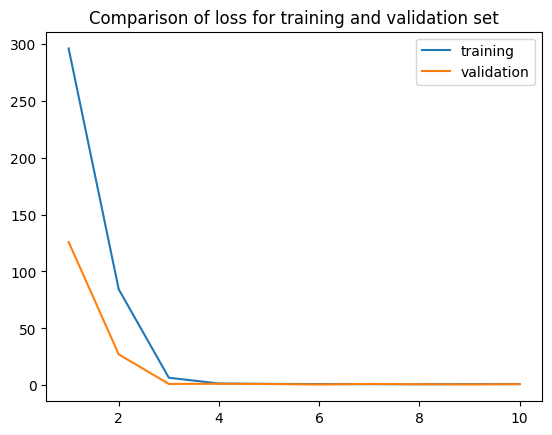

In [77]:
sns.lineplot(x=x,y=history.history["loss"],label="training")
sns.lineplot(x=x,y=history.history["val_loss"],label="validation")
plt.title("Comparison of loss for training and validation set")
plt.legend()
plt.show()

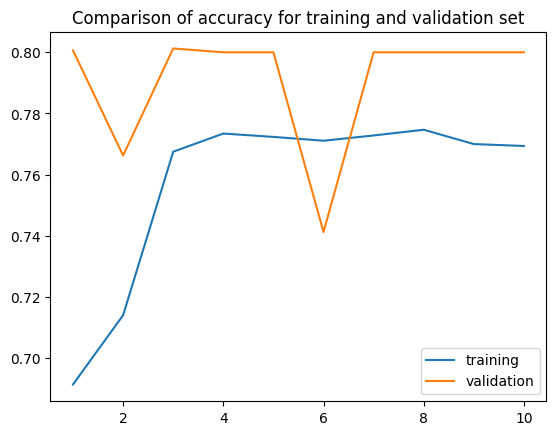

In [78]:
sns.lineplot(x=x,y=history.history["accuracy"],label="training")
sns.lineplot(x=x,y=history.history["val_accuracy"],label="validation")
plt.title("Comparison of accuracy for training and validation set")
plt.legend()
plt.show()

In [79]:
# prediction on the testing set
y_pred = model.predict(X_test)

63/63 [==============================] - 0s 2ms/step


In [80]:
# printing the model predictions
y_pred

array([[1.4444111e-09],
       [7.8176538e-07],
       [7.6001853e-04],
       ...,
       [2.9716954e-01],
       [2.9716954e-01],
       [2.9716954e-01]], dtype=float32)

# If you see than there are not labels like 0 or 1 rather there are values from 0-1, it is because we used sigmoid function in the output layer that gives values from 0-1.

In [83]:
import numpy as np
from sklearn.metrics import accuracy_score

In [85]:
# using a threshold of 0.5, above 1 below 0, 
# value greater than 0.5 than 1 else 0
y_predictions = np.where(y_pred > 0.5,1,0)

In [86]:
# compting accuracy score
score = accuracy_score(y_test,y_predictions)

In [87]:
# printing the score
score

0.799